# 21 Entailment atau NLI

Menilai apakah teks kedua didukung oleh teks pertama. Contoh: dataset WReTE, sangat kecil dengan 300 pasangan latih.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Menilai apakah satu teks mendukung teks lain |
| **Unit prediksi** | Satu pasangan teks mendapat label biner |
| **Metrik** | Macro-F1 |
| **Masalah terbesar** | Data sangat kecil (300 latih, 100 test), jadi interval lebar. Kedua kalimat juga sangat mirip, dan perbedaan kecil seperti negasi menentukan label. |
| **Data contoh** | WReTE: 300 latih, 50 valid, 100 test |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** data berisi pasangan teks dengan label mendukung atau tidak. Termasuk cek klaim terhadap sumber,
misalnya klaim MBG terhadap berita. Kalau targetnya skor, pakai folder `20`.

**Yang perlu diganti kalau datanya beda:**
- `read_split`, kolom `sent_A`, `sent_B`, `label`.
- `ENTAIL_LABEL`, nama label positif.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: hanya fitur kata, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
ENTAIL_LABEL = "Entail_or_Paraphrase"

SETTINGS = {
    "cepat": {"epochs": 5, "seeds": [SEED]},
    "penuh": {"epochs": 8, "seeds": [SEED, SEED + 1, SEED + 2, SEED + 3, SEED + 4]},
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'epochs': 8, 'seeds': [42, 43, 44, 45, 46]}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Training transformer.** Satu fungsi untuk klasifikasi (`problem="ce"`), multi-label (`"bce"`),
dan regresi (`"mse"`). Loop-nya ditulis sendiri supaya mudah dibaca dan outputnya bersih.

In [6]:
from torch.utils.data import DataLoader, TensorDataset  # noqa: E402
from transformers import (  # noqa: E402
    AutoModelForSequenceClassification,
    AutoTokenizer as _SeqTokenizer,
    get_linear_schedule_with_warmup,
)


def _encode(tokenizer, texts, pairs, max_len):
    args = (list(texts), list(pairs)) if pairs is not None else (list(texts),)
    tokens = tokenizer(
        *args, padding="max_length", truncation=True, max_length=max_len, return_tensors="pt"
    )
    return tokens["input_ids"], tokens["attention_mask"]


def _loss_fn(problem, weights):
    if problem == "ce":
        return torch.nn.CrossEntropyLoss(weight=weights)
    # untuk multi-label, class_weights berperan sebagai pos_weight per label
    return (
        torch.nn.BCEWithLogitsLoss(pos_weight=weights) if problem == "bce" else torch.nn.MSELoss()
    )


def _to_output(logits, problem):
    if problem == "ce":
        return torch.softmax(logits.float(), dim=1)
    if problem == "bce":
        return torch.sigmoid(logits.float())
    return logits.float().squeeze(-1)


@torch.inference_mode()
def _predict(model, ids, mask, problem, batch_size):
    model.eval()
    chunks = []
    for start in range(0, len(ids), batch_size):
        batch_ids = ids[start : start + batch_size].to(DEVICE)
        batch_mask = mask[start : start + batch_size].to(DEVICE)
        with torch.autocast("cuda", enabled=DEVICE == "cuda"):
            logits = model(input_ids=batch_ids, attention_mask=batch_mask).logits
        chunks.append(_to_output(logits, problem).cpu())
    return torch.cat(chunks).numpy()


def train_predict(
    model_name,
    train_texts,
    train_y,
    predict_sets,
    problem="ce",
    num_labels=None,
    class_weights=None,
    train_pairs=None,
    epochs=3,
    lr=2e-5,
    batch_size=32,
    max_len=128,
    seed=42,
):
    """Latih satu model, lalu kembalikan prediksi untuk tiap set di predict_sets.

    predict_sets: daftar teks, atau daftar pasangan (teks, teks_pair) untuk tugas dua teks.
    """
    seed_everything(seed)
    tokenizer = _SeqTokenizer.from_pretrained(MODEL_DIR / model_name)
    num_labels = num_labels or (int(np.max(train_y)) + 1 if problem == "ce" else 1)
    if problem == "bce":
        num_labels = np.asarray(train_y).shape[1]
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_DIR / model_name, num_labels=num_labels, ignore_mismatched_sizes=True
    ).to(DEVICE)

    ids, mask = _encode(tokenizer, train_texts, train_pairs, max_len)
    target = torch.tensor(np.asarray(train_y), dtype=torch.long if problem == "ce" else torch.float)
    if problem == "mse":
        target = target.view(-1, 1)
    loader = DataLoader(
        TensorDataset(ids, mask, target),
        batch_size=batch_size,
        shuffle=True,
        drop_last=len(ids) > batch_size,
    )
    weights = (
        None if class_weights is None else torch.tensor(class_weights, dtype=torch.float).to(DEVICE)
    )
    loss_fn = _loss_fn(problem, weights)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    total_steps = max(1, epochs * len(loader))
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")

    model.train()
    for _ in range(epochs):
        for batch_ids, batch_mask, batch_y in loader:
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast("cuda", enabled=DEVICE == "cuda"):
                logits = model(
                    input_ids=batch_ids.to(DEVICE), attention_mask=batch_mask.to(DEVICE)
                ).logits
                loss = loss_fn(logits, batch_y.to(DEVICE))
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()

    outputs = []
    for item in predict_sets:
        texts, pairs = item if isinstance(item, tuple) else (item, None)
        pred_ids, pred_mask = _encode(tokenizer, texts, pairs, max_len)
        outputs.append(_predict(model, pred_ids, pred_mask, problem, batch_size * 2))
    del model, optimizer, scaler
    torch.cuda.empty_cache()
    return outputs

**Fungsi gambar confusion matrix**, dipakai di bagian post-analysis.

In [7]:
from sklearn.metrics import confusion_matrix  # noqa: E402


def plot_confusion(y_true, y_pred, names, title="Confusion matrix") -> None:
    matrix = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(4.8, 3.8))
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ticks = range(len(names))
    ax.set(
        xticks=ticks,
        yticks=ticks,
        xticklabels=names,
        yticklabels=names,
        title=title,
        xlabel="prediksi",
        ylabel="asli",
    )
    ax.grid(False)
    for (row, col), value in np.ndenumerate(matrix):
        ax.text(col, row, f"{value:.2f}", ha="center", va="center")
    fig.colorbar(image)
    plt.tight_layout()
    plt.show()

## 4. EDA

Muat data. Datanya berasal dari revisi Wikipedia, jadi banyak pasangan yang hampir sama persis.

In [8]:
from sklearn.metrics import f1_score  # noqa: E402
from sklearn.model_selection import StratifiedKFold  # noqa: E402
from transformers import AutoModelForSequenceClassification as NliModel  # noqa: E402
from transformers import AutoTokenizer as NliTokenizer  # noqa: E402


def read_split(split: str) -> pd.DataFrame:
    path = EXTRA_DATA_DIR / "indonlu/dataset/wrete_entailment-ui" / f"{split}_preprocess.csv"
    return pd.read_csv(path, encoding_errors="ignore").head(N_ROWS)


train, valid, test = read_split("train"), read_split("valid"), read_split("test")
print(f"latih={len(train)} | valid={len(valid)} | test={len(test)}")
print("proporsi positif:", round((train["label"] == ENTAIL_LABEL).mean(), 3))
train[["sent_A", "sent_B", "label"]].head(3)

latih=300 | valid=50 | test=100
proporsi positif: 0.61


,sent_A,sent_B,label
0,Pada awalnya bangsa Israel hanya terdiri dari satu kelompok keluarga di antara banyak ...,Pada awalnya bangsa Yahudi hanya terdiri dari satu kelompok keluarga di antara banyak ...,NotEntail
1,"Salah satu tekniknya adalah periplus , deskripsi pada pelabuhan dan daratan sepanjang ...",Bangsa Romawi memberi sumbangan pada pemetaan karena mereka banyak menjelajahi negeri ...,NotEntail
2,Etnolinguistik antropologi adalah ilmu yang mempelajari pelukisan tentang ciri dan tat...,Etnolinguistik antropologi adalah ilmu yang mempelajari suku-suku bangsa yang ada di d...,NotEntail


Seberapa berbeda dua kalimat dalam satu pasangan, per kelas.

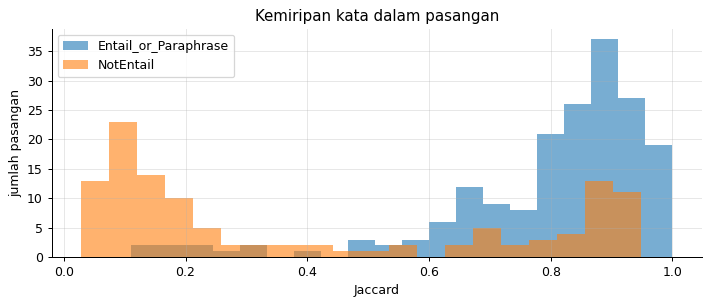

{'Entail_or_Paraphrase': 0.85, 'NotEntail': 0.209}


In [9]:
def word_overlap(a: str, b: str) -> float:
    set_a, set_b = set(a.lower().split()), set(b.lower().split())
    return len(set_a & set_b) / max(len(set_a | set_b), 1)


train["overlap"] = [word_overlap(a, b) for a, b in zip(train["sent_A"], train["sent_B"])]
fig, ax = plt.subplots()
for label, part in train.groupby("label"):
    part["overlap"].plot.hist(bins=20, alpha=0.6, ax=ax, label=label)
ax.set(title="Kemiripan kata dalam pasangan", xlabel="Jaccard", ylabel="jumlah pasangan")
ax.legend()
plt.tight_layout()
plt.show()
print(train.groupby("label")["overlap"].median().round(3).to_dict())

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| Test hanya 100 baris | Valid digabung ke latih untuk CV, jangan percaya selisih kecil |
| Kalimat hampir sama | Negasi dan angka tidak diubah |
| Proporsi positif 61% | Macro-F1 dipakai dan threshold difit di OOF |

## 5. Preprocessing

Pembersihan ringan, dan negasi serta angka tidak diubah karena sangat menentukan. Label dijadikan 0 dan 1.

In [10]:
for frame in (train, valid, test):
    frame["a"], frame["b"] = frame["sent_A"].map(clean_text), frame["sent_B"].map(clean_text)
    frame["y"] = (frame["label"] == ENTAIL_LABEL).astype(int)
y_train, y_valid, y_test = train["y"].to_numpy(), valid["y"].to_numpy(), test["y"].to_numpy()

## 6. Validasi

Valid dan test sangat kecil, jadi interval noise-nya lebar. Karena itu valid digabung ke latih untuk
cross-validation, dan test hanya untuk laporan. Metriknya macro-F1.

In [11]:
def macro_f1(y_true, y_pred) -> float:
    return float(f1_score(y_true, y_pred, average="macro", zero_division=0))


assert abs(macro_f1([0, 0, 1, 1], [0, 1, 1, 1]) - (2 / 3 + 0.8) / 2) < 1e-9
pool = pd.concat([train, valid], ignore_index=True)
y = pool["y"].to_numpy()
folds = np.zeros(len(pool), dtype=int)
for fold, (_, val_idx) in enumerate(
    StratifiedKFold(5, shuffle=True, random_state=SEED).split(pool, y)
):
    folds[val_idx] = fold
results: list[dict] = []


def bootstrap_width(y_true, y_pred, n_boot: int = 300) -> str:
    rng = np.random.default_rng(SEED)
    scores = [
        macro_f1(y_true[p], y_pred[p])
        for p in (rng.integers(0, len(y_true), len(y_true)) for _ in range(n_boot))
    ]
    return f"{np.percentile(scores, 2.5):.3f}-{np.percentile(scores, 97.5):.3f}"


def record(name: str, oof, holdout) -> None:
    results.append(
        {
            "model": name,
            "oof": round(macro_f1(y, oof), 4),
            "oof_ci95": bootstrap_width(y, oof),
            "test": round(macro_f1(y_test, holdout), 4),
        }
    )
    print(results[-1])

## 7. Baseline

Tebak mayoritas, lalu regresi logistik dari fitur perbedaan: kemiripan kata, selisih panjang, kata baru, angka,
dan negasi.

In [12]:
NEGATIONS = {"tidak", "bukan", "belum", "tanpa", "jangan", "tak"}


def pair_features(frame: pd.DataFrame) -> np.ndarray:
    rows = []
    for a, b in zip(frame["a"], frame["b"]):
        set_a, set_b = set(a.split()), set(b.split())
        rows.append(
            [
                word_overlap(a, b),
                len(set_b - set_a) / max(len(set_b), 1),
                len(set_a - set_b) / max(len(set_a), 1),
                len(set_b) / max(len(set_a), 1),
                len(NEGATIONS & set_a) != len(NEGATIONS & set_b),
                set(re.findall(r"\d+", a)) != set(re.findall(r"\d+", b)),
            ]
        )
    return np.array(rows, dtype=float)


majority = np.bincount(y).argmax()
record("mayoritas", np.full(len(y), majority), np.full(len(y_test), majority))
x_pool, x_test = pair_features(pool), pair_features(test)
oof_lr, hold_lr = np.zeros(len(y)), np.zeros(len(y_test))
for fold in range(5):
    fit, val = folds != fold, folds == fold
    model = LogisticRegression(max_iter=2000, class_weight="balanced").fit(x_pool[fit], y[fit])
    oof_lr[val] = model.predict_proba(x_pool[val])[:, 1]
    hold_lr += model.predict_proba(x_test)[:, 1] / 5
record("fitur_perbedaan", (oof_lr >= 0.5).astype(int), (hold_lr >= 0.5).astype(int))

{'model': 'mayoritas', 'oof': 0.3794, 'oof_ci95': '0.359-0.398', 'test': 0.3789}


{'model': 'fitur_perbedaan', 'oof': 0.7988, 'oof_ci95': '0.753-0.840', 'test': 0.7926}


## 8. Model Utama

**NLI pretrained (mDeBERTa):** sudah dilatih untuk entailment, jadi tidak butuh latihan, cocok untuk data kecil
seperti ini. **Cross-encoder IndoBERT:** dilatih dari nol pada data ini, dengan beberapa seed karena datanya kecil.

In [13]:
@torch.inference_mode()
def pretrained_entailment(frame: pd.DataFrame, batch_size: int = 32) -> np.ndarray:
    tokenizer = NliTokenizer.from_pretrained(MODEL_DIR / "mdeberta_nli")
    model = NliModel.from_pretrained(MODEL_DIR / "mdeberta_nli").to(DEVICE).eval()
    entail = model.config.label2id.get("entailment", 0)
    chunks = []
    for start in range(0, len(frame), batch_size):
        tokens = tokenizer(
            frame["a"].iloc[start : start + batch_size].tolist(),
            frame["b"].iloc[start : start + batch_size].tolist(),
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt",
        ).to(DEVICE)
        chunks.append(torch.softmax(model(**tokens).logits.float(), 1)[:, entail].cpu())
    del model
    torch.cuda.empty_cache()
    return torch.cat(chunks).numpy()


oof_nli, hold_nli = oof_lr, hold_lr
oof_cross, hold_cross = oof_lr, hold_lr
if USE_PRETRAINED:
    with stage("nli_pretrained"):
        oof_nli, hold_nli = pretrained_entailment(pool), pretrained_entailment(test)
    record("nli_pretrained_0_5", (oof_nli >= 0.5).astype(int), (hold_nli >= 0.5).astype(int))
    with stage("cross_encoder"):
        oof_cross, hold_cross = np.zeros(len(y)), np.zeros(len(y_test))
        for seed in SETTINGS["seeds"]:
            for fold in range(5):
                fit, val = folds != fold, folds == fold
                pred_val, pred_hold = train_predict(
                    "indobert",
                    pool.loc[fit, "a"].tolist(),
                    y[fit],
                    [
                        (pool.loc[val, "a"].tolist(), pool.loc[val, "b"].tolist()),
                        (test["a"].tolist(), test["b"].tolist()),
                    ],
                    num_labels=2,
                    train_pairs=pool.loc[fit, "b"].tolist(),
                    epochs=SETTINGS["epochs"],
                    seed=seed + fold,
                    batch_size=16,
                )
                oof_cross[val] += pred_val[:, 1] / len(SETTINGS["seeds"])
                hold_cross += pred_hold[:, 1] / (5 * len(SETTINGS["seeds"]))
    record("cross_encoder_0_5", (oof_cross >= 0.5).astype(int), (hold_cross >= 0.5).astype(int))

[waktu] nli_pretrained: 32 detik


{'model': 'nli_pretrained_0_5', 'oof': 0.8791, 'oof_ci95': '0.843-0.913', 'test': 0.8827}


[waktu] cross_encoder: 514 detik


{'model': 'cross_encoder_0_5', 'oof': 0.7571, 'oof_ci95': '0.704-0.805', 'test': 0.7868}


## 9. Post-processing

Gabungkan tiga sumber dengan regresi logistik, sebagai stacking di dalam fold. Threshold ikut difit dari fold
lain, jadi skornya tetap jujur.

In [14]:
def best_threshold(scores, target) -> float:
    grid = np.arange(0.2, 0.81, 0.02)
    return float(grid[int(np.argmax([macro_f1(target, scores >= t) for t in grid]))])


stack_pool = np.column_stack([oof_lr, oof_nli, oof_cross])
stack_test = np.column_stack([hold_lr, hold_nli, hold_cross])
oof_stack, hold_stack = np.zeros(len(y)), np.zeros(len(y_test))
oof_pred = np.zeros(len(y), dtype=int)
for fold in range(5):
    fit, val = folds != fold, folds == fold
    stacker = LogisticRegression(C=1.0, max_iter=2000).fit(stack_pool[fit], y[fit])
    fit_scores = stacker.predict_proba(stack_pool[fit])[:, 1]
    oof_stack[val] = stacker.predict_proba(stack_pool[val])[:, 1]
    oof_pred[val] = oof_stack[val] >= best_threshold(fit_scores, y[fit])
    hold_stack += stacker.predict_proba(stack_test)[:, 1] / 5
hold_pred = (hold_stack >= best_threshold(oof_stack, y)).astype(int)
record("stacking_plus_threshold", oof_pred, hold_pred)

{'model': 'stacking_plus_threshold', 'oof': 0.8748, 'oof_ci95': '0.836-0.907', 'test': 0.9132}


## 10. Post-analysis

**Tabel perbandingan.** Perhatikan lebarnya interval, karena data kecil membuat selisih kecil tidak berarti.

In [15]:
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table

,model,oof,oof_ci95,test
0,mayoritas,0.3794,0.359-0.398,0.3789
1,fitur_perbedaan,0.7988,0.753-0.840,0.7926
2,nli_pretrained_0_5,0.8791,0.843-0.913,0.8827
3,cross_encoder_0_5,0.7571,0.704-0.805,0.7868
4,stacking_plus_threshold,0.8748,0.836-0.907,0.9132


**Confusion matrix OOF.**

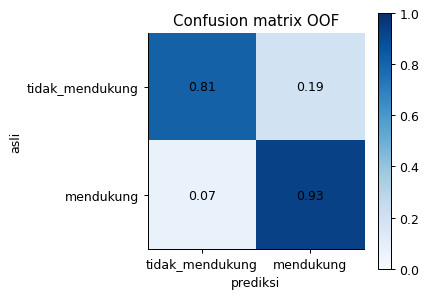

In [16]:
plot_confusion(y, oof_pred, ["tidak_mendukung", "mendukung"], "Confusion matrix OOF")

**Salah prediksi.** Biasanya pasangan yang katanya hampir sama tapi maknanya berubah.

In [17]:
errors = pool.assign(pred=oof_pred)
errors[errors["y"] != errors["pred"]][["a", "b", "y", "pred"]].head(6)

,a,b,y,pred
0,pada awalnya bangsa israel hanya terdiri dari satu kelompok keluarga di antara banyak ...,pada awalnya bangsa yahudi hanya terdiri dari satu kelompok keluarga di antara banyak ...,0,1
2,etnolinguistik antropologi adalah ilmu yang mempelajari pelukisan tentang ciri dan tat...,etnolinguistik antropologi adalah ilmu yang mempelajari suku-suku bangsa yang ada di d...,0,1
38,masing-masing jenis tembang macapat memiliki jumlah gatra yang berbeda-beda dan untuk ...,sekar macapat atau tembang macapat dapat diartikan sebagai salah satu bentuk sekar ( t...,0,1
57,"chairil masuk hollands inlandsche school ( his ) , sekolah dasar untuk orang-orang pri...","chairil masuk sekolah widya merti ( his ) , sekolah dasar untuk orang-orang pribumi wa...",0,1
70,di daerah selatan borneo suku dayak pernah membangun sebuah kerajaan .,di daerah selatan kalimantan suku dayak pernah membangun sebuah kerajaan .,1,0
72,"pada tahun 1953 , churchil dianugrahkan penghargaan nobel di bidang literarur karena s...","pada tahun 1953 , churchill dianugerahi penghargaan nobel di bidang sastra karena sumb...",1,0


## 11. Keluaran

File untuk dikumpulkan dan ringkasan run.

In [18]:
pd.DataFrame({"id": test.index, "label": hold_pred}).to_csv(
    RESULT_DIR / "submission.csv", index=False
)
run_summary(
    "nli",
    len(pool),
    {r["model"]: {"oof": r["oof"], "test": r["test"]} for r in results},
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=nli mode=penuh n_rows=350 total_detik=560 gpu=True
{
 "mayoritas": {
  "oof": 0.3794,
  "test": 0.3789
 },
 "fitur_perbedaan": {
  "oof": 0.7988,
  "test": 0.7926
 },
 "nli_pretrained_0_5": {
  "oof": 0.8791,
  "test": 0.8827
 },
 "cross_encoder_0_5": {
  "oof": 0.7571,
  "test": 0.7868
 },
 "stacking_plus_threshold": {
  "oof": 0.8748,
  "test": 0.9132
 }
}


**Poin untuk presentasi**

- Model NLI pretrained tanpa latihan sudah 0,8827 di test, dan melatih cross-encoder dari 300 baris hanya 0,7868.
- Stacking test 0,9132, tapi OOF-nya 0,8748 dan lebih rendah dari pretrained 0,8791. Dengan 100 baris test, selisih ini belum bisa disebut nyata.
- **Kalau label sedikit, coba model pretrained dulu** sebelum melatih sendiri.